In [655]:
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [656]:
import pandas as pd

test = pd.read_csv('data/test.csv')
train = pd.read_csv('data/train.csv')

test.info()

<class 'pandas.DataFrame'>
RangeIndex: 4277 entries, 0 to 4276
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   4277 non-null   str    
 1   HomePlanet    4190 non-null   str    
 2   CryoSleep     4184 non-null   object 
 3   Cabin         4177 non-null   str    
 4   Destination   4185 non-null   str    
 5   Age           4186 non-null   float64
 6   VIP           4184 non-null   object 
 7   RoomService   4195 non-null   float64
 8   FoodCourt     4171 non-null   float64
 9   ShoppingMall  4179 non-null   float64
 10  Spa           4176 non-null   float64
 11  VRDeck        4197 non-null   float64
 12  Name          4183 non-null   str    
dtypes: float64(6), object(2), str(5)
memory usage: 434.5+ KB


In [657]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB


In [658]:
# try to use a logistic regression to estimate it 
# plan 
# 1. clean the data
# 2. feature engineering
# 3. regression with scikit

In [659]:
data1 = {
    "A" : ["1", "2", "3"],
    "B" : ["4", "5", "6"],
    "C" : ["7", "8", "9"]
}
data2 = {
    "A" : ["11", "22", "33"],
    "B" : ["44", "55", "66"],
    "C" : ["77", "88", "99"]
}
dataF1 = pd.DataFrame(data1)
dataF2 = pd.DataFrame(data2)

pd.concat([dataF1, dataF2], axis=1,ignore_index=True)

,0,1,2,3,4,5
0,1,4,7,11,44,77
1,2,5,8,22,55,88
2,3,6,9,33,66,99


In [660]:
df

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,HomePlanet_Earth,...,TotalSpend,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Deck_Unknown
0,0,39.0,0,0.0,0.0,0.0,0.0,0.0,False,0,...,0.0,0,1,0,0,0,0,0,0,0
1,0,24.0,0,109.0,9.0,25.0,549.0,44.0,True,1,...,736.0,0,0,0,0,0,1,0,0,0
2,0,58.0,1,43.0,3576.0,0.0,6715.0,49.0,False,0,...,10383.0,1,0,0,0,0,0,0,0,0
3,0,33.0,0,0.0,1283.0,371.0,3329.0,193.0,False,0,...,5176.0,1,0,0,0,0,0,0,0,0
4,0,16.0,0,303.0,70.0,151.0,565.0,2.0,True,1,...,1091.0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12965,1,34.0,0,0.0,0.0,0.0,0.0,0.0,False,1,...,0.0,0,0,0,0,0,0,1,0,0
12966,0,42.0,0,0.0,847.0,17.0,10.0,144.0,False,1,...,1018.0,0,0,0,0,0,0,0,0,1
12967,1,NaN,0,0.0,0.0,0.0,0.0,0.0,False,0,...,0.0,0,0,0,1,0,0,0,0,0
12968,0,NaN,0,0.0,2680.0,0.0,0.0,523.0,False,0,...,3203.0,0,0,0,1,0,0,0,0,0


# Data cleaning

In [661]:
# merging both test and train to do the same thing to all data 
print(test.shape)
print(train.shape)

test["Transported"] = False;
df = pd.concat([train, test], ignore_index=True, axis=0)

(4277, 13)
(8693, 14)


In [662]:
# passengers who spent cannot be in cryosleep 
purchase_cols = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

cond = (df[purchase_cols].sum(axis=1) > 0) & (df["CryoSleep"].isna())
df.loc[cond, "CryoSleep"] = False

In [663]:
df.isna().sum() / df.count() * 100

PassengerId     0.000000
HomePlanet      2.270935
CryoSleep       1.059685
Cabin           2.359719
Destination     2.158160
Age             2.125984
VIP             2.335490
RoomService     2.069725
FoodCourt       2.279000
ShoppingMall    2.416298
Spa             2.238688
VRDeck          2.109904
Name            2.319344
Transported     0.000000
dtype: float64

In [664]:
# separate the GroupID and the PassengerID 
df[["GroupId", "PassengerId"]] = df["PassengerId"].str.split("_", expand=True)

In [665]:
# fill na for HomePlanet and Destination based on GroupID
cols = ["HomePlanet", "Destination"]

def fill_from_group(s):
    m = s.mode()
    if m.empty:
        return s
    return s.fillna(m.iloc[0])

df[cols] = df.groupby("GroupId")[cols].transform(fill_from_group)

In [666]:
dummy_cols = ["HomePlanet", "Destination"] 
for col in dummy_cols:
    dummies = pd.get_dummies(df[col], dummy_na=True, dtype=int, prefix=col)
    dummies = dummies.rename(columns={f"{col}_nan": f"{col}_Unknown"})
    df = pd.concat([df, dummies], axis = 1)

df = df.drop(columns=dummy_cols)

df.columns

Index(['PassengerId', 'CryoSleep', 'Cabin', 'Age', 'VIP', 'RoomService',
       'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name', 'Transported',
       'GroupId', 'HomePlanet_Earth', 'HomePlanet_Europa', 'HomePlanet_Mars',
       'HomePlanet_Unknown', 'Destination_55 Cancri e',
       'Destination_PSO J318.5-22', 'Destination_TRAPPIST-1e',
       'Destination_Unknown'],
      dtype='str')

In [667]:
# split Cabin just because
df[["Deck", "Num", "Side"]] = df["Cabin"].str.split("/", expand=True)
df = df.drop(columns="Cabin")

In [668]:
# drop name
df = df.drop(columns="Name")

In [669]:
# add total spend category
spend_cols = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
df["TotalSpend"] = df[spend_cols].sum(axis=1)

In [670]:
# make zero spenders true for cryosleep
df.loc[(df["TotalSpend"] == 0) & (df["CryoSleep"].isna()), "CryoSleep"] = True

In [671]:
# VIP na = False
df.loc[df["VIP"].isna(), "VIP"] = False

In [672]:
# change values to int
df["Num"] = pd.to_numeric(df["Num"])
df[["CryoSleep", "VIP"]] = df[["CryoSleep", "VIP"]].astype(int)

In [673]:
# one-hot for Deck 
dummies = pd.get_dummies(df["Deck"], dummy_na=True,dtype=int, prefix="Deck")
dummies = dummies.rename(columns={"Deck_nan": "Deck_Unknown"})
df = pd.concat([df, dummies], axis=1)
df = df.drop(columns="Deck")

In [674]:
# 0/1 for side
df["Side"] = df["Side"].map({"P":0, "S":1})

In [675]:
# drop group and passenger id
df = df.drop(columns=["GroupId", "PassengerId"])

# Simple Imputation 

In [676]:
from sklearn.impute import SimpleImputer

In [689]:
train_X, test_X = df.drop(columns=["Transported"])[:train.shape[0]], df.drop(columns=["Transported"])[train.shape[0]:]
train_Y = df["Transported"][:train.shape[0]]

impute_settings = [
    (SimpleImputer(strategy="median"), ["Age", "Num"]),
    (SimpleImputer(strategy="constant", fill_value=0), ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]),
    (SimpleImputer(strategy="most_frequent"), ["Side"])
]

for imp, cols in impute_settings:
    train_X[cols] = imp.fit_transform(train_X[cols])
    test_X[cols] = imp.transform(test_X[cols])

# Training / Eval

In [690]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

train_X_split, test_X_split, train_Y_split, test_Y_split = train_test_split(train_X, train_Y, test_size = 0.2, random_state = 42)

model_1 = LogisticRegression()
model_1.fit(train_X_split, train_Y_split)
pred = model_1.predict(test_X_split)
accuracy_score(test_Y_split, pred)

/Users/chinmunyau/Coding Stuff/[04] AI/05 - ICAIC/JupyterNotebooks-MY/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.7740080506037953

In [691]:
# Logistic regression with cross_val_score and StratifiedShuffleSplit
from sklearn.model_selection import cross_val_score, StratifiedShuffleSplit

holdout = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
cross_val_score(model_1, train_X, train_Y, cv=holdout)

/Users/chinmunyau/Coding Stuff/[04] AI/05 - ICAIC/JupyterNotebooks-MY/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


array([0.78838413])

In [692]:
# HistGradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model_2 = HistGradientBoostingClassifier(random_state=42)

scores = cross_val_score(model_2, train_X, train_Y, cv=cv, scoring="accuracy")
print(f"{scores.mean():.4f} +/- {scores.std():.4f}")

0.8087 +/- 0.0054


# Submission

In [694]:
model_2.fit(train_X, train_Y)
y_pred = model_2.predict(test_X)

submission = pd.DataFrame({
    "PassengerId":test["PassengerId"],
    "Transported":y_pred.astype(bool)
})

submission.to_csv("submission1.csv", index=False)

# Stats

In [630]:
df_imp = pd.concat([train_X, test_X], axis=0)
df_imp.isna().sum()

CryoSleep                       0
Age                             0
VIP                             0
RoomService                     0
FoodCourt                       0
ShoppingMall                    0
Spa                             0
VRDeck                          0
HomePlanet_Earth                0
HomePlanet_Europa               0
HomePlanet_Mars                 0
HomePlanet_Unknown              0
Destination_55 Cancri e         0
Destination_PSO J318.5-22       0
Destination_TRAPPIST-1e         0
Destination_Unknown             0
Num                             0
Side                            0
TotalSpend                      0
Deck_A                          0
Deck_B                          0
Deck_C                          0
Deck_D                          0
Deck_E                          0
Deck_F                          0
Deck_G                          0
Deck_T                          0
Deck_Unknown                    0
Transported                  8693
dtype: int64

In [631]:
df_imp.info()

<class 'pandas.DataFrame'>
RangeIndex: 12970 entries, 0 to 12969
Data columns (total 29 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CryoSleep                  12970 non-null  int64  
 1   Age                        12970 non-null  float64
 2   VIP                        12970 non-null  int64  
 3   RoomService                12970 non-null  float64
 4   FoodCourt                  12970 non-null  float64
 5   ShoppingMall               12970 non-null  float64
 6   Spa                        12970 non-null  float64
 7   VRDeck                     12970 non-null  float64
 8   HomePlanet_Earth           12970 non-null  int64  
 9   HomePlanet_Europa          12970 non-null  int64  
 10  HomePlanet_Mars            12970 non-null  int64  
 11  HomePlanet_Unknown         12970 non-null  int64  
 12  Destination_55 Cancri e    12970 non-null  int64  
 13  Destination_PSO J318.5-22  12970 non-null  int64  
 14  D

<Axes: >

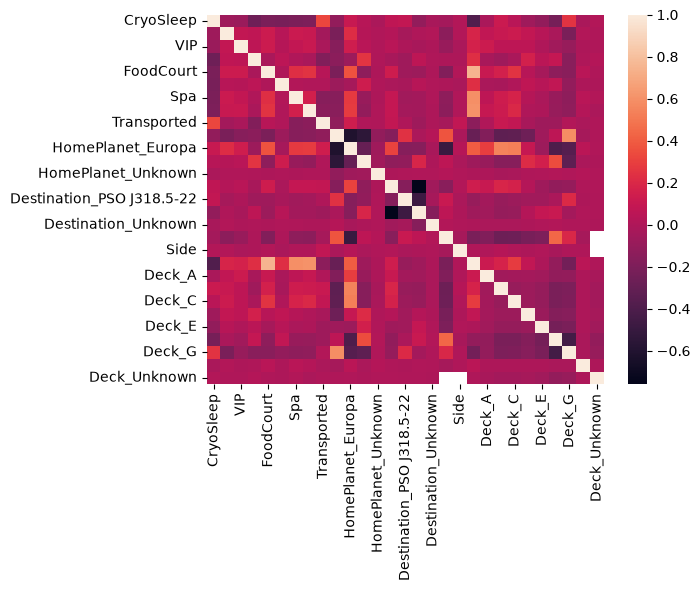

In [608]:
sns.heatmap(df.corr())

# Reflections
### What I learnt
- Data cleaning
- Data imputation (simple imputer, KNN imputer)
### What I need to learn
- StratifiedKFold vs train_test_split
- How training works